# 01 · ResNet18 training

Trains the spectral model on ASVspoof 2019 LA train, selects the checkpoint on dev, and saves it with everything inference needs. No eval-set data is read here; scoring happens in notebook 03.

Inputs: notebook 00 output, `audio_utils.py` and `rawboost.py`. Requires a GPU and Internet (ImageNet weights).



ImageNet-initialised ResNet18 with stem and `layer1` frozen, head `BN → Dropout(0.3) → Linear`, AdamW (lr 1e-4, weight decay 1e-4), batch 64, up to 20 epochs, LR halved after 3 epochs without dev-loss improvement, early stopping after 5 epochs without dev-EER improvement once 8 epochs have run.

In [1]:
import json
import math
import os
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision.models import ResNet18_Weights, resnet18

INPUT_ROOT = "/kaggle/input"
WORK_DIR = "/kaggle/working"
SEED = 0
BATCH_SIZE = 64
EPOCHS = 20
MIN_EPOCHS = 8
PATIENCE = 5
LR = 1e-4
WEIGHT_DECAY = 1e-4
CLASS_WEIGHT = {"bonafide": 0.9, "spoof": 0.1}
SPEC_F_MAX, SPEC_T_MAX = 20, 40
NUM_WORKERS = os.cpu_count()
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
AMP = DEVICE.type == "cuda"
torch.backends.cudnn.benchmark = True
print(f"torch {torch.__version__}, {torch.cuda.get_device_name(0) if AMP else 'CPU only'}", flush=True)

torch 2.11.0+cu128, Tesla T4


In [2]:
def find_dir(required, max_depth=6):
    hits = set()
    for dirpath, dirnames, filenames in os.walk(INPUT_ROOT):
        depth = os.path.relpath(dirpath, INPUT_ROOT).count(os.sep)
        dirnames[:] = [] if depth >= max_depth else sorted(d for d in dirnames if d not in ("flac", "cache"))
        if set(required) <= set(filenames):
            hits.add(os.path.realpath(dirpath))
    if len(hits) != 1:
        raise FileNotFoundError(f"expected one directory with {required} under {INPUT_ROOT}, found {sorted(hits)}")
    return hits.pop()


for module_file in ("audio_utils.py", "rawboost.py"):
    sys.path.insert(0, find_dir([module_file]))
import audio_utils as U  # noqa: E402
import rawboost  # noqa: E402

U._self_test()
PREP_DIR = find_dir(["manifest.csv", "feature_stats.json", "provenance.json"])
with open(os.path.join(PREP_DIR, "provenance.json")) as fh:
    prep = json.load(fh)
for name, path in [("manifest", "manifest.csv"), ("feature_stats", "feature_stats.json")]:
    if U.file_sha256(os.path.join(PREP_DIR, path)) != prep[f"{name}_sha256"]:
        raise AssertionError(f"{path} does not match provenance.json")
for split in ("train", "dev"):
    if U.file_sha256(os.path.join(PREP_DIR, prep["cache"][split]["file"])) != prep["cache"][split]["sha256"]:
        raise AssertionError(f"{split} cache does not match provenance.json")

manifest = pd.read_csv(os.path.join(PREP_DIR, "manifest.csv"))
with open(os.path.join(PREP_DIR, "feature_stats.json")) as fh:
    stats = U.FeatureStats.from_dict(json.load(fh))
train_df = manifest[manifest["split"] == "train"].reset_index(drop=True)
dev_df = manifest[manifest["split"] == "dev"].reset_index(drop=True)
print(f"prep outputs from audio_utils {prep['utils_version']}, running {U.UTILS_VERSION}")
print(PREP_DIR, len(train_df), len(dev_df), DEVICE)

audio_utils 1.0.1 self-test passed (sha 658e72bce982)
prep outputs from audio_utils 1.0.1, running 1.0.1
/kaggle/input/notebooks/rudranshiverma/00-data-prep 25380 24844 cuda:0


## Data

Workers read int16 audio from the cache and return 4 s float waveforms; features are computed on the GPU. RawBoost runs on the full clip before cropping, as in the official implementation.

In [3]:
class CachedAudio(Dataset):
    def __init__(self, df, split, train):
        self.offsets = df["cache_offset"].to_numpy()
        self.lengths = df["n_samples"].to_numpy()
        self.labels = df["label"].to_numpy().astype(np.float32)
        self.path = os.path.join(PREP_DIR, prep["cache"][split]["file"])
        self.train = train
        self.cache = None

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        if self.cache is None:
            self.cache = np.memmap(self.path, dtype="<i2", mode="r")
        o, n = self.offsets[i], self.lengths[i]
        x = U.int16_to_float32(np.array(self.cache[o:o + n]))
        if self.train:
            x = rawboost.rawboost_la(x)
            if n > U.MAX_SAMPLES:
                start = np.random.randint(0, n - U.MAX_SAMPLES + 1)
                x = x[start:start + U.MAX_SAMPLES]
        return U.fit_head(torch.from_numpy(x)), torch.tensor(self.labels[i])


def make_loader(df, split, train, seed=SEED):
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(
        CachedAudio(df, split, train), batch_size=BATCH_SIZE, shuffle=train, drop_last=train,
        num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=NUM_WORKERS > 0,
        worker_init_fn=U.seed_worker, generator=g,
    )


features = U.LogMelDelta(stats).to(DEVICE)


def spec_augment(x, gen):
    b, _, n_f, n_t = x.shape
    f_w = torch.randint(0, SPEC_F_MAX + 1, (b,), generator=gen, device=x.device)
    t_w = torch.randint(0, SPEC_T_MAX + 1, (b,), generator=gen, device=x.device)
    f_0 = (torch.rand(b, generator=gen, device=x.device) * (n_f - f_w)).long()
    t_0 = (torch.rand(b, generator=gen, device=x.device) * (n_t - t_w)).long()
    f = torch.arange(n_f, device=x.device)[None, :]
    t = torch.arange(n_t, device=x.device)[None, :]
    f_mask = (f >= f_0[:, None]) & (f < (f_0 + f_w)[:, None])
    t_mask = (t >= t_0[:, None]) & (t < (t_0 + t_w)[:, None])
    keep = ~(f_mask[:, None, :, None] | t_mask[:, None, None, :])
    return x * keep

## Model

In [4]:
FROZEN = ("conv1", "bn1", "layer1")


class FP32Head(nn.Sequential):
    """Keeps logits in fp32 under autocast; fp16 logits create ties that coarsen EER."""

    def forward(self, x):
        with torch.autocast(x.device.type, enabled=False):
            return super().forward(x.float())


def build_model(pretrained=True):
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    for name, p in model.named_parameters():
        p.requires_grad = not name.startswith(FROZEN)
    model.fc = FP32Head(nn.BatchNorm1d(model.fc.in_features), nn.Dropout(0.3), nn.Linear(model.fc.in_features, 1))
    return model.to(DEVICE)


def set_train_mode(model):
    model.train()
    for name in FROZEN:
        getattr(model, name).eval()


def weighted_bce(logits, labels):
    w = torch.where(labels == U.LABEL_BONAFIDE, CLASS_WEIGHT["bonafide"], CLASS_WEIGHT["spoof"])
    loss = F.binary_cross_entropy_with_logits(logits.float(), labels, reduction="none")
    return (w * loss).sum() / w.sum()


@torch.no_grad()
def predict(model, loader):
    model.eval()
    logits, labels, loss_sum, weight_sum = [], [], 0.0, 0.0
    for wave, y in loader:
        wave, y = wave.to(DEVICE, non_blocking=True), y.to(DEVICE)
        x = features(wave)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
            out = model(x).squeeze(1)
        w = torch.where(y == U.LABEL_BONAFIDE, CLASS_WEIGHT["bonafide"], CLASS_WEIGHT["spoof"])
        loss_sum += (w * F.binary_cross_entropy_with_logits(out.float(), y, reduction="none")).sum().item()
        weight_sum += w.sum().item()
        logits.append(out.float().cpu())
        labels.append(y.cpu())
    return torch.cat(labels).numpy().astype(int), torch.cat(logits).numpy(), loss_sum / weight_sum


model = build_model()
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable parameters: {n_train:,} of {sum(p.numel() for p in model.parameters()):,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 202MB/s]


trainable parameters: 11,020,545 of 11,178,049


## Pre-flight checks

Normalised features of clean train audio must be zero-mean and unit-variance per channel. The network must then be able to memorise 64 clips; if it cannot, the training loop or labels are broken and the full run would be wasted.

In [5]:
U.seed_everything(SEED)
clean = CachedAudio(train_df.sample(256, random_state=SEED), "train", train=False)
clean_wave = torch.stack([clean[i][0] for i in range(len(clean))]).to(DEVICE)
U.check_feature_batch(features(clean_wave))

t0 = time.time()
aug = CachedAudio(train_df.sample(200, random_state=SEED), "train", train=True)
_ = [aug[i] for i in range(len(aug))]
per_clip = (time.time() - t0) / len(aug)
print(f"RawBoost + loading: {per_clip * 1000:.0f} ms per clip, "
      f"~{per_clip * len(train_df) / max(NUM_WORKERS, 1) / 60:.1f} min of CPU per epoch with {NUM_WORKERS} workers")

tiny_df = pd.concat([train_df[train_df["label"] == 0].sample(32, random_state=SEED),
                     train_df[train_df["label"] == 1].sample(32, random_state=SEED)])
tiny = CachedAudio(tiny_df, "train", train=False)
tiny_wave = torch.stack([tiny[i][0] for i in range(len(tiny))]).to(DEVICE)
tiny_y = torch.tensor(tiny.labels, device=DEVICE)
probe = build_model()
opt = torch.optim.AdamW([p for p in probe.parameters() if p.requires_grad], lr=1e-3)
with torch.no_grad():
    tiny_x = features(tiny_wave)
for step in range(150):
    set_train_mode(probe)
    loss = weighted_bce(probe(tiny_x).squeeze(1), tiny_y)
    opt.zero_grad(set_to_none=True)
    loss.backward()
    opt.step()
probe.eval()
with torch.no_grad():
    tiny_logits = probe(tiny_x).squeeze(1).float().cpu().numpy()
tiny_eer, _ = U.eer(tiny.labels.astype(int), tiny_logits)
print(f"overfit test: loss {loss.item():.4f}, EER {tiny_eer:.3f}")
if tiny_eer > 0 or loss.item() > 0.05:
    raise AssertionError("model cannot memorise 64 clips")
del probe, opt

RawBoost + loading: 43 ms per clip, ~4.5 min of CPU per epoch with 4 workers
overfit test: loss 0.0000, EER 0.000


## Training

In [6]:
U.seed_everything(SEED)
model = build_model()
optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)
scaler = torch.amp.GradScaler(DEVICE.type, enabled=AMP)
train_loader = make_loader(train_df, "train", train=True)
dev_loader = make_loader(dev_df, "dev", train=False)
gen = torch.Generator(device=DEVICE)
gen.manual_seed(SEED)

ckpt_path = os.path.join(WORK_DIR, f"resnet18_seed{SEED}.pt")
history, best_eer, best_epoch, stale = [], math.inf, 0, 0
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    set_train_mode(model)
    loss_sum = 0.0
    for wave, y in train_loader:
        wave, y = wave.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        x = spec_augment(features(wave), gen)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
            logits = model(x).squeeze(1)
        loss = weighted_bce(logits, y)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        loss_sum += loss.item()
    labels, logits, dev_loss = predict(model, dev_loader)
    dev_eer, dev_thr = U.eer(labels, logits)
    scheduler.step(dev_loss)
    row = {"epoch": epoch, "train_loss": loss_sum / len(train_loader), "dev_loss": dev_loss, "dev_eer": dev_eer,
           "lr": optimizer.param_groups[0]["lr"], "seconds": time.time() - t0}
    history.append(row)
    improved = dev_eer < best_eer
    if improved:
        best_eer, best_epoch, stale = dev_eer, epoch, 0
        torch.save({"model_state_dict": model.state_dict(), "epoch": epoch, "dev_eer": dev_eer,
                    "dev_threshold_logit": dev_thr}, ckpt_path)
    elif epoch >= MIN_EPOCHS:
        stale += 1
    print(f"epoch {epoch:2d}  train {row['train_loss']:.4f}  dev loss {dev_loss:.4f}  dev EER {dev_eer:.4%}  "
          f"lr {row['lr']:.1e}  {row['seconds']:.0f} s{'  *' if improved else ''}")
    if stale >= PATIENCE:
        print(f"early stop: no dev EER improvement for {PATIENCE} epochs")
        break
print(f"best dev EER {best_eer:.4%} at epoch {best_epoch}")

epoch  1  train 0.4299  dev loss 0.3126  dev EER 8.3509%  lr 1.0e-04  427 s  *
epoch  2  train 0.2442  dev loss 0.2748  dev EER 6.3897%  lr 1.0e-04  413 s  *
epoch  3  train 0.1601  dev loss 0.3034  dev EER 6.0803%  lr 1.0e-04  416 s  *
epoch  4  train 0.1250  dev loss 0.4115  dev EER 4.1987%  lr 1.0e-04  411 s  *
epoch  5  train 0.0989  dev loss 0.4611  dev EER 5.2225%  lr 1.0e-04  411 s
epoch  6  train 0.0833  dev loss 0.3320  dev EER 4.8973%  lr 5.0e-05  408 s
epoch  7  train 0.0648  dev loss 0.1439  dev EER 2.5605%  lr 5.0e-05  410 s  *
epoch  8  train 0.0583  dev loss 0.3874  dev EER 4.7493%  lr 5.0e-05  408 s
epoch  9  train 0.0481  dev loss 0.4670  dev EER 5.2976%  lr 5.0e-05  437 s
epoch 10  train 0.0528  dev loss 0.1845  dev EER 2.8257%  lr 5.0e-05  460 s
epoch 11  train 0.0492  dev loss 0.4769  dev EER 5.4215%  lr 2.5e-05  444 s
epoch 12  train 0.0413  dev loss 0.3813  dev EER 3.7278%  lr 2.5e-05  430 s
early stop: no dev EER improvement for 5 epochs
best dev EER 2.5605% at e

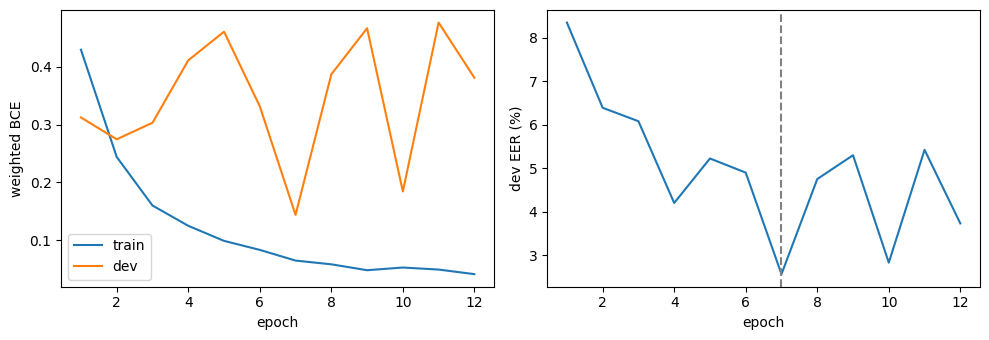

,epoch,train_loss,dev_loss,dev_eer,lr,seconds
0,1,0.42990,0.31257,0.08351,0.00010,427.31968
1,2,0.24424,0.27482,0.06390,0.00010,413.18539
2,3,0.16014,0.30342,0.06080,0.00010,415.56786
3,4,0.12503,0.41150,0.04199,0.00010,410.81448
4,5,0.09892,0.46114,0.05222,0.00010,410.77058
5,6,0.08330,0.33199,0.04897,0.00005,407.53506
6,7,0.06479,0.14392,0.02560,0.00005,409.55579
7,8,0.05832,0.38736,0.04749,0.00005,407.87682
8,9,0.04811,0.46704,0.05298,0.00005,437.04056
9,10,0.05276,0.18452,0.02826,0.00005,460.05674


In [7]:
hist = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(hist["epoch"], hist["train_loss"], label="train")
ax[0].plot(hist["epoch"], hist["dev_loss"], label="dev")
ax[0].set_xlabel("epoch")
ax[0].set_ylabel("weighted BCE")
ax[0].legend()
ax[1].plot(hist["epoch"], hist["dev_eer"] * 100)
ax[1].axvline(best_epoch, color="grey", linestyle="--")
ax[1].set_xlabel("epoch")
ax[1].set_ylabel("dev EER (%)")
plt.tight_layout()
plt.show()
hist.round(5)

## Final checkpoint

The best weights are reloaded and dev is re-scored; the result must reproduce the EER recorded during training, and agree with an independent EER implementation. The checkpoint then gets the configuration and provenance needed by notebooks 03–04 and the backend.

In [8]:
best = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
final = build_model(pretrained=False)
final.load_state_dict(best["model_state_dict"])
labels, logits, _ = predict(final, make_loader(dev_df, "dev", train=False))
dev_eer, dev_thr = U.eer(labels, logits)
step = 1.0 / min((labels == 0).sum(), (labels == 1).sum())
if abs(dev_eer - best["dev_eer"]) > step:
    raise AssertionError(f"reloaded dev EER {dev_eer} != recorded {best['dev_eer']}")
if abs(dev_eer - U.eer_independent(labels, logits)) > 1.5 * step:
    raise AssertionError("official and independent EER disagree")

rates = U.rates_at_threshold(labels, logits, dev_thr)
checkpoint = {
    "model_state_dict": best["model_state_dict"],
    "model": "resnet18",
    "epoch": best["epoch"],
    "seed": SEED,
    "dev_eer": dev_eer,
    "threshold_logit": dev_thr,
    "threshold_prob": float(torch.sigmoid(torch.tensor(dev_thr))),
    "threshold_source": "dev_eer",
    "feature_stats": stats.to_dict(),
    "frozen": list(FROZEN),
    "config": {"batch_size": BATCH_SIZE, "epochs": EPOCHS, "min_epochs": MIN_EPOCHS, "patience": PATIENCE, "lr": LR,
               "weight_decay": WEIGHT_DECAY, "class_weight": CLASS_WEIGHT, "spec_augment": [SPEC_F_MAX, SPEC_T_MAX],
               "rawboost": {"algo": 5, **rawboost.LNL, **rawboost.ISD}, "amp": AMP},
    "history": history,
    "utils_sha256": U.utils_sha256(),
    "prep_manifest_sha256": prep["manifest_sha256"],
    "versions": {"torch": torch.__version__},
}
torch.save(checkpoint, ckpt_path)
print(json.dumps({k: checkpoint[k] for k in ("epoch", "dev_eer", "threshold_logit", "threshold_prob")}, indent=2))
pd.Series(rates).to_frame("dev at dev-EER threshold")

{
  "epoch": 7,
  "dev_eer": 0.02560494057687661,
  "threshold_logit": 2.4378979206085205,
  "threshold_prob": 0.919671893119812
}


,dev at dev-EER threshold
threshold_logit,2.437898
tp,21723.000000
tn,2483.000000
fp,65.000000
fn,573.000000
spoof_recall,0.974300
spoof_precision,0.997017
bonafide_rejection_rate,0.025510
spoof_miss_rate,0.025700
accuracy,0.974320
